# 03 — Machine Learning Model Experiments

## Objective
Train and compare multiclass classification models to predict
student mental health risk: Low, Medium, or High.

## Models
- Logistic Regression
- Random Forest
- XGBoost

## Evaluation strategy
- Stratified 5-Fold Cross-Validation
- Primary metric: Macro F1-score
- Secondary metrics: Accuracy, Precision, Recall
- Hold-out test set reserved for final evaluation

### Import data

In [21]:
import pandas as pd
import numpy as np
import joblib


from pathlib import Path
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier


from sklearn.preprocessing import LabelEncoder

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score, 
    f1_score, 
    recall_score, 
    precision_score,
    classification_report, 
    confusion_matrix
)


RANDOM_STATE = 42

### Load artifacts

In [30]:
PROJECT_ROOT = Path.cwd().parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"

train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")


preprocessor = joblib.load(
    MODELS_DIR / "preprocessor.joblib"
)


TARGET = "Mental_Health_Risk"


X_train = train_df.drop(columns=[TARGET])
y_train = train_df[TARGET]


X_test = test_df.drop(columns=[TARGET])
y_test = test_df[TARGET]


print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (1600, 15)
y_train: (1600,)
X_test: (400, 15)
y_test: (400,)


### Verify the data

In [31]:
print("Training target distribution:")
print(y_train.value_counts())

print("\nMissing target labels:")
print(y_train.isna().sum())

print("\nFeature columns:")
print(X_train.columns.tolist())
print(len(X_train.columns))

assert X_train.shape[1] == 15
assert y_train.isna().sum() == 0
assert list(X_train.columns) == list(X_test.columns)

print("\nData validation passed!")

Training target distribution:
Mental_Health_Risk
High      544
Medium    528
Low       528
Name: count, dtype: int64

Missing target labels:
0

Feature columns:
['Age', 'Gender', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Physical_Activity', 'Financial_Stress', 'Family_Support', 'Attendance_Rate', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']
15

Data validation passed!


### Define Stratified K-Fold

In [32]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)


lr_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])


lr_results = cross_validate(
    lr_pipeline,
    X_train, 
    y_train, 
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision_macro": "precision_macro",
        "recall_macro": "recall_macro",
        "f1_macro": "f1_macro"
    },
    n_jobs=-1
)


print("Mean Accuracy:", lr_results["test_accuracy"].mean())
print("Mean Precision:", lr_results["test_precision_macro"].mean())
print("Mean Recall:", lr_results["test_recall_macro"].mean())
print("Mean F1-score:", lr_results["test_f1_macro"].mean())

Mean Accuracy: 0.75125
Mean Precision: 0.7513095951866806
Mean Recall: 0.7506960033386669
Mean F1-score: 0.7502740507332312


### Training and evaluating Random Forest

In [33]:
rf_pipeline = Pipeline(
    [("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=1
    ))]
)


rf_results = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision_macro": "precision_macro",
        "f1_macro": "f1_macro",
        "recall_macro": "recall_macro"
    }
)


print("Mean Accuracy:", rf_results["test_accuracy"].mean())
print("Mean Precision:", rf_results["test_precision_macro"].mean())
print("Mean Recall:", rf_results["test_recall_macro"].mean())
print("Mean F1-score:", rf_results["test_f1_macro"].mean())


Mean Accuracy: 0.689375
Mean Precision: 0.6807979475755943
Mean Recall: 0.6882235948123665
Mean F1-score: 0.6825352907790425


### XGBoost training and evaluation

In [34]:
xgb_pipeline = Pipeline(
    [
        ("preprocessor", clone(preprocessor)),
        ("classifier", XGBClassifier(
            objective="multi:softprob",
            num_class=3,
            max_depth=4,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="mlogloss",
            random_state=RANDOM_STATE,
            learning_rate=0.1, 
            n_estimators=100,
            n_jobs=1
        ))
    ]
)

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)

xgb_results = cross_validate(
    xgb_pipeline,
    X_train, 
    y_train_encoded,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision_macro": "precision_macro",
        "f1_macro": "f1_macro",
        "recall_macro": "recall_macro"
    },
    n_jobs=-1
)



### Random Forest vs Logistic Regression vs XGBoost


In [35]:
comparison_df = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": lr_results["test_accuracy"].mean(),
        "Precision": lr_results["test_precision_macro"].mean(),
        "Recall": lr_results["test_recall_macro"].mean(),
        "F1 Macro": lr_results["test_f1_macro"].mean()
    },
    {
        "Model": "Random Forest",
        "Accuracy": rf_results["test_accuracy"].mean(),
        "Precision": rf_results["test_precision_macro"].mean(),
        "Recall": rf_results["test_recall_macro"].mean(),
        "F1 Macro": rf_results["test_f1_macro"].mean()
    },
{
        "Model": "XGBoost",
        "Accuracy": xgb_results["test_accuracy"].mean(),
        "Precision": xgb_results["test_precision_macro"].mean(),
        "Recall": xgb_results["test_recall_macro"].mean(),
        "F1 Macro": xgb_results["test_f1_macro"].mean()
    }
])

comparison_df = comparison_df.sort_values(
    by="F1 Macro",
    ascending=False
)

display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Macro
0,Logistic Regression,0.7512,0.7513,0.7507,0.7503
2,XGBoost,0.6894,0.6877,0.6885,0.6874
1,Random Forest,0.6894,0.6808,0.6882,0.6825


### Examining the f1 score macro across all folds

In [36]:
comparison_df = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": results["test_accuracy"].mean(),
        "F1 Macro": results["test_f1_macro"].mean(),
        "F1 Std": results["test_f1_macro"].std()
    }
    for name, results in {
        "Logistic Regression": lr_results,
        "Random Forest": rf_results,
        "XGBoost": xgb_results
    }.items()
])

display(
    comparison_df.sort_values(
        "F1 Macro", ascending=False
    ).round(4)
)

,Model,Accuracy,F1 Macro,F1 Std
0,Logistic Regression,0.7512,0.7503,0.0234
2,XGBoost,0.6894,0.6874,0.0193
1,Random Forest,0.6894,0.6825,0.0271


### HyperParameter tuning ( optimization)

In [39]:
from sklearn.model_selection import RandomizedSearchCV
xgb_param_distributions = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [2, 3, 4, 5, 6],
    "classifier__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "classifier__subsample": [0.7, 0.8, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 1.0]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_param_distributions,
    # n_iter=20,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1
)

xgb_search.fit(X_train, y_train_encoded)

# print("\nthe best hyperparameters")
# print(xgb_search.best_params_)
# print("\nthe best cv macro f1")
# print(xgb_search.best_score_)
# print("\nthe best estimator")
# print(xgb_search.best_estimator_)


rf_param_distribution = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [None, 3, 5, 10],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2"]
}
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_distribution,
    # n_iter=20,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1
)

rf_search.fit(X_train, y_train)

lr_param_distribution = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"]
}
# lr_params_v2 = [
#     {
#         "classifier__solver": ["lbfgs"],
#         "classifier__penalty": ["l2"],
#         "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
#         "classifier__class_weight": [None, "balanced"]
#     },
#     {
#         "classifier__solver": ["saga"],
#         "classifier__penalty": ["l1", "l2"],
#         "classifier__C": [0.01, 0.1, 1, 10],
#         "classifier__class_weight": [None, "balanced"]
#     }
# ]
lr_search = RandomizedSearchCV(
    estimator=lr_pipeline,
    param_distributions=lr_param_distribution,
    # n_iter=20,
    scoring="f1_macro",
    cv=cv,
    random_state=RANDOM_STATE, 
    n_jobs=-1,
    verbose=1
)


lr_search.fit(X_train, y_train)
search_result = {
    "index": [
        "XGBoost",
        "Logistic Regression",
        "Random Forest"
        ],
    "the best hyperparameters": [
        xgb_search.best_params_, 
        lr_search.best_params_, 
        rf_search.best_params_
        ],
    "the best cv macro f1": [
        xgb_search.best_score_, 
        lr_search.best_score_, 
        rf_search.best_score_
        ],
    "the best estimator": [
        xgb_search.best_estimator_, 
        lr_search.best_estimator_, 
        rf_search.best_estimator_
        ]

}

search_result_df = pd.DataFrame(search_result).set_index("index")
search_result_df.sort_values("the best cv macro f1", ascending=False)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Fitting 5 folds for each of 10 candidates, totalling 50 fits


,the best hyperparameters,the best cv macro f1,the best estimator
index,,,
Logistic Regression,"{'classifier__class_weight': 'balanced', 'clas...",0.751696,"(ColumnTransformer(transformers=[('num',\n ..."
XGBoost,"{'classifier__subsample': 0.8, 'classifier__n_...",0.698526,"(ColumnTransformer(transformers=[('num',\n ..."
Random Forest,"{'classifier__n_estimators': 100, 'classifier_...",0.680310,"(ColumnTransformer(transformers=[('num',\n ..."


### Evaluation on test data

Best model: Logistic Regression
Best CV Macro F1: 0.7516955367384908
Test Accuracy:  0.7575
Test Macro F1:  0.75778404358299


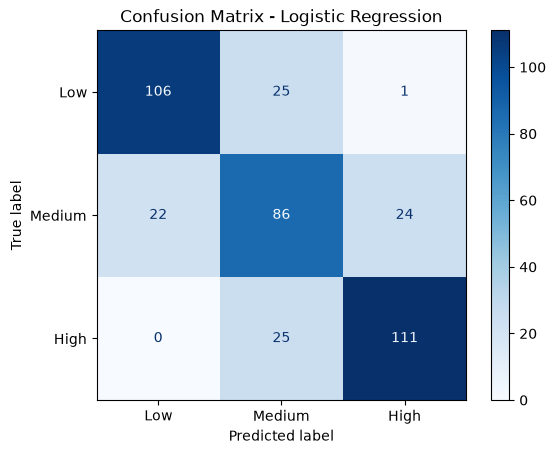

In [48]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score, 
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

best_model_name = search_result_df[
    "the best cv macro f1"
].idxmax()

searches = {
    "XGBoost": xgb_search,
    "Logistic Regression": lr_search,
    "Random Forest": rf_search
}

best_model = searches[best_model_name].best_estimator_

print("Best model:", best_model_name)
print("Best CV Macro F1:", searches[best_model_name].best_score_)

y_pred = best_model.predict(X_test)

if best_model_name == "XGBoost":
    y_pred = label_encoder.inverse_transform(
        y_pred.astype(int)
    )

print("Test Accuracy: ", accuracy_score(y_test, y_pred))
print("Test Macro F1: ", f1_score(
    y_test, y_pred, average="macro"
))

ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred, 
    labels=["Low", "Medium", "High"],
    cmap="Blues",
    values_format="d"
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.savefig(
    FIGURES_DIR / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Save the model

In [41]:
import joblib
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    best_model,
    MODELS_DIR / "best_model.joblib"
)

print("Model saved successfully.")

Model saved successfully.


### Save reports

In [51]:

from pathlib import Path
import json
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent


REPORTS_DIR = PROJECT_ROOT / "reports"
METRICS_DIR = REPORTS_DIR / "metrics"
FIGURES_DIR = REPORTS_DIR / "figures"


METRICS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

labels = ["Low", "Medium", "High"]
report = classification_report(
    y_test, 
    y_pred, 
    labels=labels,
    output_dict=True,
    zero_division=0

)


pd.DataFrame(report).T.to_csv(
    METRICS_DIR / "classification_report.csv"
)



# pd.DataFrame(report).T


cm = confusion_matrix(
    y_test,
    y_pred, 
    labels=labels
)

pd.DataFrame(
    cm,
    index=labels,
    columns=labels
).to_csv(METRICS_DIR / "confusion_matrix.csv")



# model comparaison

search_result_df.to_csv(
    METRICS_DIR / "model_comparaison.csv"
)


# best model metadata

metadata = {
    "model_name": best_model_name, 
    "cv_macro_f1": float(
        searches[best_model_name].best_score_
    ),
    "test_macro_f1": float(
        report["macro avg"]["f1-score"]
    ),
    "test_accuracy": float(report["accuracy"]),
    "test_samples": len(y_test),
    "classes": labels
}

with open(REPORTS_DIR / "best_model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Reports saved to: ", REPORTS_DIR)

Reports saved to:  /home/moali/projects/student-mental-health-ml/reports
